In [14]:
import requests
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

In [3]:
#Cargar de datos 
# 1. Agregamos el sufijo :avg a las series diarias para promediar el mes entero
ids_series = "147.3_IBIENESNIA_DICI_T_20,90.1_BMCMT_0_0_42,92.2_TIPO_CAMBIION_0_0_21_24:avg,89.1_TIB_0_0_20:avg,174.1_RRVAS_IDOS_0_0_36,143.3_NO_PR_2004_A_21"

url = f"https://apis.datos.gob.ar/series/api/series?ids={ids_series}&format=json&collapse=month&limit=5000"

respuesta = requests.get(url)

if respuesta.status_code == 200:
    datos = respuesta.json()
    nombres_columnas = ['fecha', 'ipc_patagonia', 'base_monetaria', 'tipo_cambio','tasa_BADLAR','saldo_reservas','EMAE']
    df = pd.DataFrame(datos['data'], columns=nombres_columnas)
    df['fecha'] = pd.to_datetime(df['fecha'])
    df.set_index('fecha', inplace=True)

    # Limpiamos el desfase de publicación del último mes
    df.dropna(inplace=True)

    # 2. Transformaciones seguras forzando el formato numérico previo al cálculo
    df['ipc_patagonia'] = df['ipc_patagonia'].astype(float).pct_change() * 100
    df['base_monetaria'] = df['base_monetaria'].astype(float).pct_change() * 100
    df['EMAE']=df['EMAE'].astype(float).pct_change()*100

    # 3. Redondeamos todo el DataFrame junto en una sola línea
    df = df.astype(float).round(2)

    # Delimitación temporal
    df = df.loc['2016-01-01':'2026-12-31']

    # Eliminamos el primer mes que quedó en NaN por culpa del pct_change()
    df.dropna(inplace=True)
    display(df.tail())
    display(df.describe())

else:
    print(f"Error {respuesta.status_code}: {respuesta.text}")

,ipc_patagonia,base_monetaria,tipo_cambio,tasa_BADLAR,saldo_reservas,EMAE
fecha,,,,,,
2025-12-01,2.63,8.06,1447.36,26.46,41167.0,3.98
2026-01-01,2.36,3.54,1449.80,31.20,44503.0,-2.84
2026-02-01,1.89,-2.20,1408.63,30.79,45566.0,-6.79
2026-03-01,2.33,-0.96,1395.98,27.57,43381.0,14.99
2026-04-01,2.57,-0.88,1381.41,22.45,44516.0,1.29


,ipc_patagonia,base_monetaria,tipo_cambio,tasa_BADLAR,saldo_reservas,EMAE
count,112.000000,112.000000,112.000000,112.000000,112.000000,112.000000
mean,4.824375,3.549554,355.174911,44.592321,42710.591339,0.240893
std,11.774464,4.504328,469.237092,24.687612,11275.186856,5.133184
min,-46.590000,-3.600000,15.340000,19.250000,21513.000000,-11.630000
25%,2.292500,0.177500,42.945000,29.717500,37616.000000,-2.842500
50%,3.365000,2.335000,97.735000,34.370000,42221.750000,-1.260000
75%,5.152500,6.217500,679.797500,50.592500,48338.575000,2.315000
max,109.660000,19.480000,1449.800000,129.350000,71662.500000,15.650000


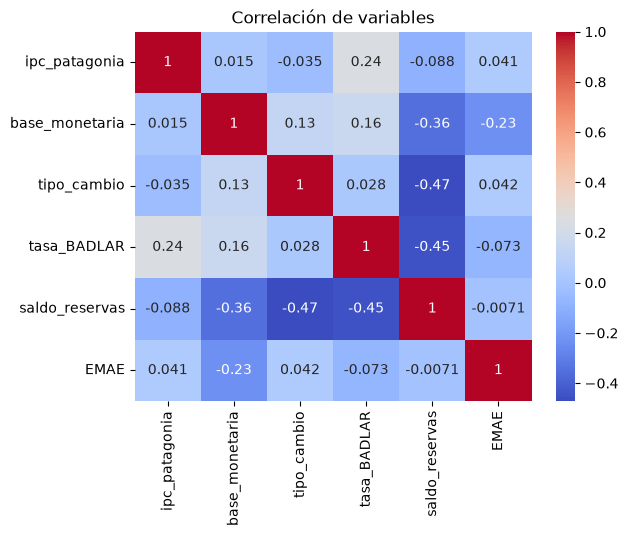

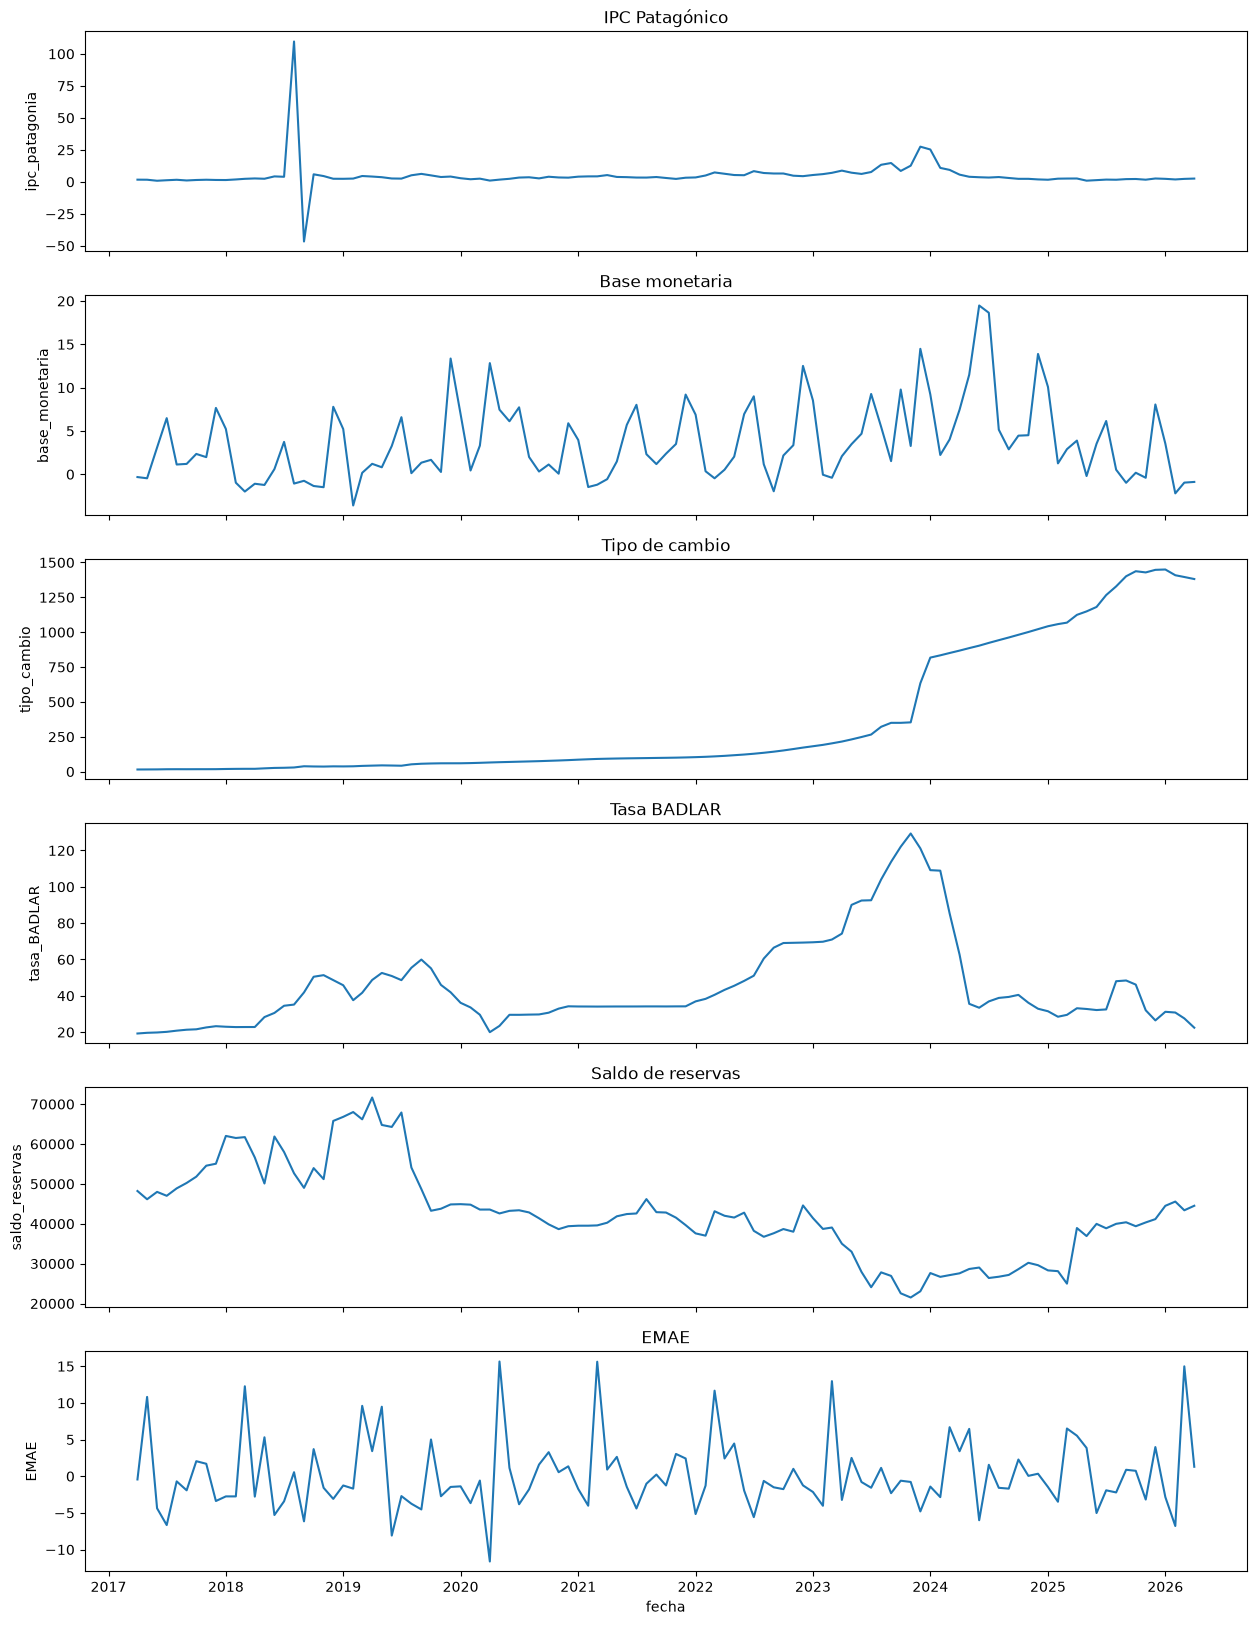

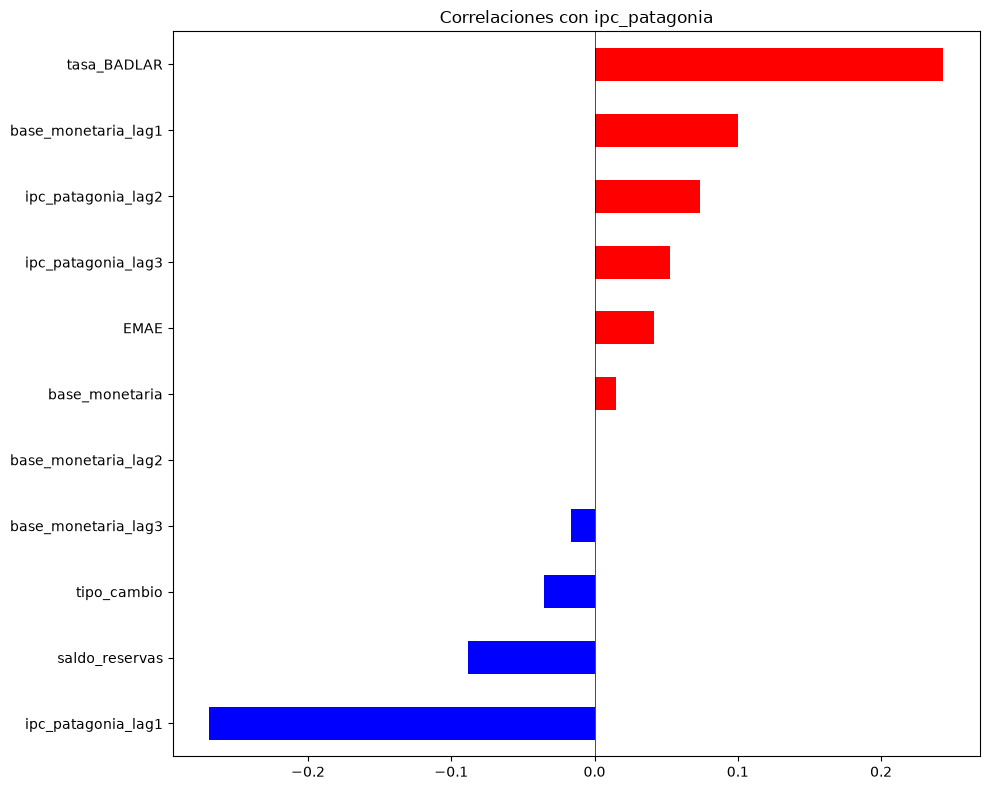

In [10]:
# Visualización de datos 
# Correlación de variables (sin rezagos)
cols_nr=['ipc_patagonia','base_monetaria','tipo_cambio','tasa_BADLAR','saldo_reservas','EMAE']
sns.heatmap(df[cols_nr].corr(),annot=True,cmap='coolwarm').set_title('Correlación de variables')
plt.show()

#Lineplot múltiple
fig, axes=plt.subplots(nrows=6, ncols=1, figsize=(15,20), sharex=True)
sns.lineplot(data=df, x=df.index, y='ipc_patagonia', ax=axes[0]).set_title('IPC Patagónico')
sns.lineplot(data=df, x=df.index, y='base_monetaria', ax=axes[1]).set_title('Base monetaria')
sns.lineplot(data=df, x=df.index, y='tipo_cambio', ax=axes[2]).set_title('Tipo de cambio')
sns.lineplot(data=df, x=df.index, y='tasa_BADLAR', ax=axes[3]).set_title('Tasa BADLAR')
sns.lineplot(data=df, x=df.index, y='saldo_reservas', ax=axes[4]).set_title('Saldo de reservas')
sns.lineplot(data=df, x=df.index, y='EMAE', ax=axes[5]).set_title('EMAE')
plt.show()

# Correlación de variables con rezagos (respecto a IPC)
target = 'ipc_patagonia'
corr = df.corr()[target].drop(target).sort_values()

plt.figure(figsize=(10, 8))
corr.plot(kind='barh', color=corr.apply(lambda x: 'red' if x > 0 else 'blue'))
plt.axvline(x=0, color='black', linewidth=0.5)
plt.title(f'Correlaciones con {target}')
plt.tight_layout()
plt.show()

In [ ]:
# Transformación de variables
#Incorporamos rezagos
df['ipc_patagonia_lag1']=df['ipc_patagonia'].shift(1)
df['ipc_patagonia_lag2']=df['ipc_patagonia'].shift(2)
df['ipc_patagonia_lag3']=df['ipc_patagonia'].shift(3)
df['base_monetaria_lag1']=df['base_monetaria'].shift(1)
df['base_monetaria_lag2']=df['base_monetaria'].shift(2)
df['base_monetaria_lag3']=df['base_monetaria'].shift(3)
df.dropna(inplace=True)



Estadístico ADF: -13.58
p-value: 0.00
La serie es ESTACIONARIA. El parámetro 'd' puede ser 0.


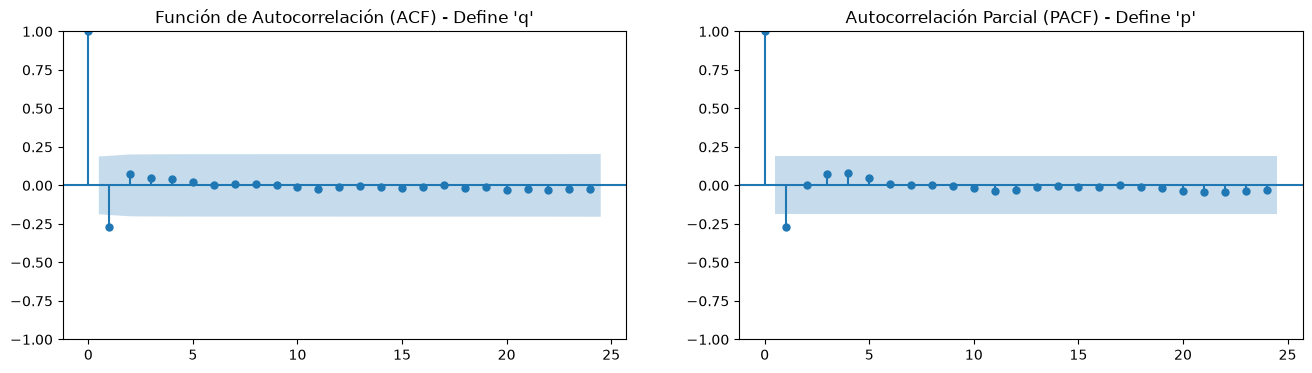

                               SARIMAX Results                                
Dep. Variable:          ipc_patagonia   No. Observations:                  109
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -420.239
Date:                Fri, 16 Oct 2026   AIC                            848.478
Time:                        00:57:46   BIC                            859.243
Sample:                    04-01-2017   HQIC                           852.844
                         - 04-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.9272      2.915      1.690      0.091      -0.786      10.641
ar.L1         -0.2659      0.412     -0.645      0.519      -1.073       0.542
ma.L1         -0.0016      0.445     -0.004      0.9

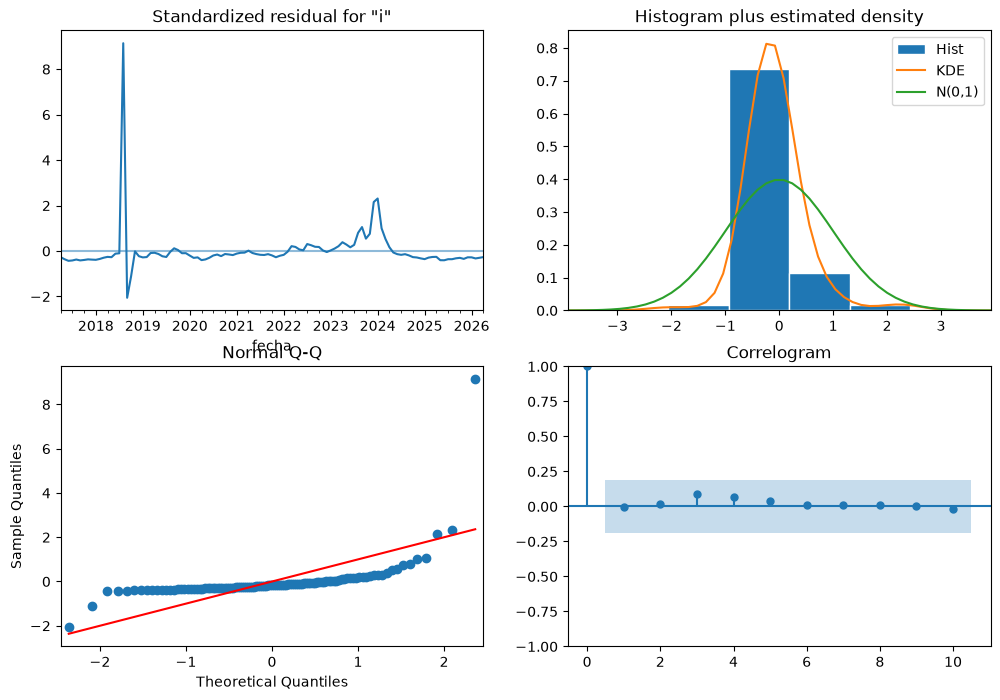

In [21]:
# ARIMA
# Extraemos la serie del IPC sin valores nulos
serie_ipc = df['ipc_patagonia'].dropna()

# Ejecutamos el test ADF
resultado_adf = adfuller(serie_ipc, result_object=True)

print(f"Estadístico ADF: {resultado_adf[0]:.2f}")
print(f"p-value: {resultado_adf[1]:.2f}")

if resultado_adf[1] < 0.05:
    print("La serie es ESTACIONARIA. El parámetro 'd' puede ser 0.")
else:
    print("La serie NO es estacionaria. Necesitas diferenciarla (d=1 o más).") 

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# Graficamos ACF y PACF con 24 rezagos (2 años de historia)
plot_acf(serie_ipc, lags=24, ax=axes[0])
axes[0].set_title("Función de Autocorrelación (ACF) - Define 'q'")

plot_pacf(serie_ipc, lags=24, ax=axes[1])
axes[1].set_title("Autocorrelación Parcial (PACF) - Define 'p'")

plt.show()

# El modelo ARIMA (p, d, q) se define con los parámetros p=1, d=0, q=1 según el análisis previo
modelo = ARIMA(serie_ipc, order=(1, 0, 1))
# Entrenamos el modelo
resultados = modelo.fit()
# Imprimimos el reporte econométrico (equivalente a la salida de EViews/Stata)
print(resultados.summary())

# Graficamos el comportamiento de los errores del modelo
fig = resultados.plot_diagnostics(figsize=(12, 8))
plt.show()